In [1]:
import os, glob, random
import numpy as np
import pandas as pd
import torch

# Reproducibility: fix every source of randomness
SEED = 42
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
set_seed(SEED)

# Paths
BASE = "/kaggle/input/datasets/khlafalshammari/competition"
TRAIN_DIR = os.path.join(BASE, "train", "train")
TEST_DIR = os.path.join(BASE, "test", "test")

# Find the cleaned metadata produced by notebook 01
meta_path = glob.glob("/kaggle/input/**/train_metadata_clean.csv", recursive=True)
print("Metadata found at:", meta_path)

# Check the GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")

Metadata found at: ['/kaggle/input/notebooks/khlafalshammari/01-eda-facial-features/train_metadata_clean.csv']
Device: cuda | Tesla T4


In [2]:
from sklearn.model_selection import train_test_split

df = pd.read_csv(meta_path[0])

# Label encoding: class name -> integer (models need numbers, not strings)
CLASSES = sorted(df["class"].unique())
class_to_idx = {c: i for i, c in enumerate(CLASSES)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
df["label"] = df["class"].map(class_to_idx)
print("Class mapping:", class_to_idx)

# Stratified 85/15 split
train_df, val_df = train_test_split(
    df, test_size=0.15, stratify=df["label"], random_state=SEED
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
print(f"\nTrain: {len(train_df)} | Validation: {len(val_df)}")

# Check: class proportions should be (almost) identical in both sets
props = pd.DataFrame({
    "train %": (train_df["class"].value_counts(normalize=True) * 100).round(2),
    "val %": (val_df["class"].value_counts(normalize=True) * 100).round(2),
})
props

Class mapping: {'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}

Train: 54098 | Validation: 9547


,train %,val %
class,,
CatEye,21.80,21.81
CatFace,10.91,10.90
CatMouth,10.91,10.90
CatNose,10.91,10.90
DogEye,18.19,18.18
DogFace,9.09,9.09
DogMouth,9.10,9.10
DogNose,9.10,9.10


In [5]:
import torchvision.transforms as T
from PIL import Image

# ---- Configuration: all key settings in one place ----
CFG = {
    "img_size": 128,      # will compare 128 vs 224 later
    "batch_size": 128,
    "num_workers": 4,     # parallel image loading on Kaggle's CPU cores
}

# ImageNet statistics: required because the backbone was pretrained on ImageNet
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

class RandomDownscale:
    """Simulates low-resolution images (Task 1: test set has 8.2% < 32 px).
    Shrinks the image; the Resize step afterwards scales it back up, leaving it blurry."""
    def __init__(self, p=0.3, min_side=16, max_side=48):
        self.p, self.min_side, self.max_side = p, min_side, max_side
    def __repr__(self):
        return f"RandomDownscale(p={self.p}, min_side={self.min_side}, max_side={self.max_side})"
        
    def __call__(self, img):
        if random.random() < self.p:
            target = random.randint(self.min_side, self.max_side)
            short = min(img.size)
            if short > target:                       # only shrink images that are bigger than the target
                scale = target / short
                new_size = (max(1, round(img.width * scale)), max(1, round(img.height * scale)))
                img = img.resize(new_size, Image.BILINEAR)
        return img

S = CFG["img_size"]

# Training: augmentation + resize + normalise
train_tf = T.Compose([
    RandomDownscale(p=0.3),
    T.Resize((S, S)),
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=10, translate=(0.05, 0.05), scale=(0.9, 1.1)),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Validation AND test: no randomness, only the deterministic steps
eval_tf = T.Compose([
    T.Resize((S, S)),
    T.ToTensor(),
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

print("Train transforms:\n", train_tf)
print("\nEval transforms:\n", eval_tf)

Train transforms:
 Compose(
    RandomDownscale(p=0.3, min_side=16, max_side=48)
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomAffine(degrees=[-10.0, 10.0], translate=(0.05, 0.05), scale=(0.9, 1.1))
    ColorJitter(brightness=(0.7, 1.3), contrast=(0.7, 1.3), saturation=(0.8, 1.2), hue=None)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Eval transforms:
 Compose(
    Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


Train: 54098 images, 422 batches
Val:   9547 images, 75 batches
Test:  29443 images, 231 batches
Batch tensor shape: torch.Size([128, 3, 128, 128])


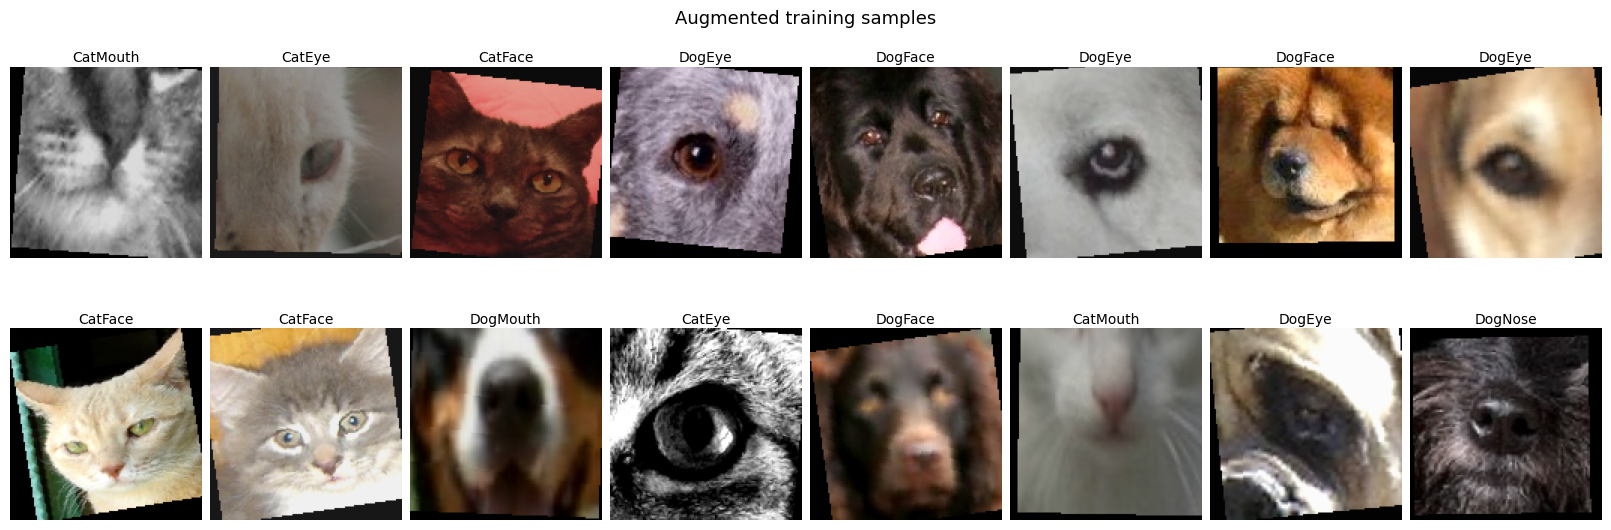

In [7]:
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

class FacialFeatureDataset(Dataset):
    """Loads images on demand. Returns (image, label) for train/val, (image, image_id) for test."""
    def __init__(self, df, img_dir, transform, has_labels=True):
        self.ids = df["image_id"].values
        self.labels = df["label"].values if has_labels else None
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        img_id = int(self.ids[idx])
        path = os.path.join(self.img_dir, f"{img_id:05d}.jpg")
        img = Image.open(path).convert("RGB")     # safety net: always 3 channels
        img = self.transform(img)
        if self.labels is not None:
            return img, int(self.labels[idx])
        return img, img_id

# Test set: use sample_submission order so predictions line up with the required IDs
test_df = pd.read_csv(os.path.join(BASE, "sample_submission.csv"))[["image_id"]]

train_ds = FacialFeatureDataset(train_df, TRAIN_DIR, train_tf)
val_ds   = FacialFeatureDataset(val_df,   TRAIN_DIR, eval_tf)
test_ds  = FacialFeatureDataset(test_df,  TEST_DIR,  eval_tf, has_labels=False)

g = torch.Generator().manual_seed(SEED)   # makes the shuffling order reproducible
loader_args = dict(batch_size=CFG["batch_size"], num_workers=CFG["num_workers"], pin_memory=True)

train_loader = DataLoader(train_ds, shuffle=True, drop_last=True, generator=g, **loader_args)
val_loader   = DataLoader(val_ds,   shuffle=False, **loader_args)
test_loader  = DataLoader(test_ds,  shuffle=False, **loader_args)

print(f"Train: {len(train_ds)} images, {len(train_loader)} batches")
print(f"Val:   {len(val_ds)} images, {len(val_loader)} batches")
print(f"Test:  {len(test_ds)} images, {len(test_loader)} batches")

# Visual check: what the model actually sees after augmentation
imgs, lbls = next(iter(train_loader))
print("Batch tensor shape:", imgs.shape)   # expect [128, 3, 128, 128]

mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)

fig, axes = plt.subplots(2, 8, figsize=(16, 5.5), constrained_layout=True)
for ax, img, lbl in zip(axes.flat, imgs[:16], lbls[:16]):
    ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0))   # undo normalisation for display
    ax.set_title(idx_to_class[lbl.item()], fontsize=10, pad=4)
    ax.axis("off")
fig.suptitle("Augmented training samples", fontsize=13)
plt.show()

In [8]:
import timm

MODEL_NAME = "convnext_tiny"
model = timm.create_model(MODEL_NAME, pretrained=True, num_classes=len(CLASSES))
model = model.to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"timm version: {timm.__version__}")
print(f"Model: {MODEL_NAME} | parameters: {n_params/1e6:.1f}M")
print("Classifier head:", model.get_classifier())

# Sanity check: one forward pass on the batch from Cell 4
model.eval()
with torch.no_grad():
    out = model(imgs[:8].to(device))
print("Output shape:", out.shape)   # expect [8, 8]: 8 images x 8 class scores

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

timm version: 1.0.29
Model: convnext_tiny | parameters: 27.8M
Classifier head: Linear(in_features=768, out_features=8, bias=True)
Output shape: torch.Size([8, 8])


Config: {'img_size': 128, 'batch_size': 128, 'num_workers': 4, 'epochs': 8, 'lr': 0.0003, 'weight_decay': 0.05, 'label_smoothing': 0.1, 'warmup_epochs': 1}


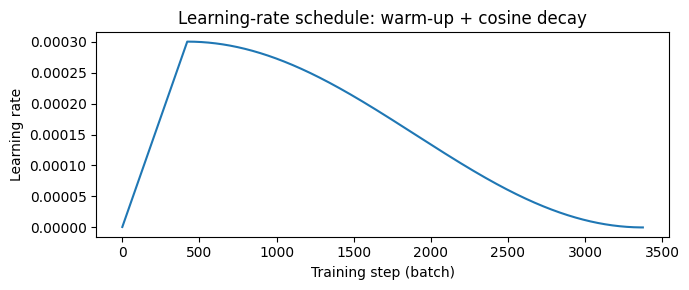

In [9]:
import math
import torch.nn as nn

CFG.update({
    "epochs": 8,
    "lr": 3e-4,
    "weight_decay": 0.05,
    "label_smoothing": 0.1,
    "warmup_epochs": 1,
})

# Loss: cross-entropy with label smoothing
criterion = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])

# Optimiser: AdamW
optimizer = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])

# Learning-rate schedule: 1 epoch linear warm-up, then cosine decay to 0 (updated every batch)
steps_per_epoch = len(train_loader)
total_steps  = CFG["epochs"] * steps_per_epoch
warmup_steps = CFG["warmup_epochs"] * steps_per_epoch

def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return 0.5 * (1 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

# Mixed precision: faster training on the T4 with almost no accuracy cost
scaler = torch.amp.GradScaler("cuda")

print("Config:", CFG)

# Plot the schedule (useful figure for the report)
plt.figure(figsize=(7, 3))
plt.plot([CFG["lr"] * lr_lambda(s) for s in range(total_steps)])
plt.title("Learning-rate schedule: warm-up + cosine decay")
plt.xlabel("Training step (batch)"); plt.ylabel("Learning rate")
plt.tight_layout(); plt.show()

In [10]:
import time
from tqdm.auto import tqdm

def train_one_epoch(model, loader):
    model.train()                                   # enables dropout/stochastic depth
    total_loss, correct, n = 0.0, 0, 0
    for x, y in tqdm(loader, desc="train", leave=False):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)       # clear old gradients
        with torch.autocast("cuda", dtype=torch.float16):   # mixed precision
            logits = model(x)
            loss = criterion(logits, y)
        scaler.scale(loss).backward()               # backpropagation
        scaler.step(optimizer)                      # update weights
        scaler.update()
        scheduler.step()                            # update learning rate (per batch)
        total_loss += loss.item() * x.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        n += x.size(0)
    return total_loss / n, correct / n

@torch.no_grad()                                    # no gradients needed for evaluation
def evaluate(model, loader):
    model.eval()                                    # disables dropout etc.
    total_loss, correct, n = 0.0, 0, 0
    all_preds, all_labels = [], []
    for x, y in tqdm(loader, desc="val", leave=False):
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(x)
            loss = criterion(logits, y)
        preds = logits.argmax(1)
        total_loss += loss.item() * x.size(0)
        correct += (preds == y).sum().item()
        n += x.size(0)
        all_preds.append(preds.cpu()); all_labels.append(y.cpu())
    return total_loss / n, correct / n, torch.cat(all_preds), torch.cat(all_labels)

# ---- Training with checkpointing and early stopping ----
CKPT_PATH = "/kaggle/working/best_model.pth"
PATIENCE = 3
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_acc, epochs_no_improve = 0.0, 0

for epoch in range(1, CFG["epochs"] + 1):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader)
    va_loss, va_acc, _, _ = evaluate(model, val_loader)

    for k, v in zip(history, [tr_loss, tr_acc, va_loss, va_acc]):
        history[k].append(v)

    print(f"Epoch {epoch}/{CFG['epochs']} | "
          f"train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
          f"val loss {va_loss:.4f} acc {va_acc:.4f} | "
          f"{time.time() - t0:.0f}s")

    if va_acc > best_acc:                           # save only when validation improves
        best_acc, epochs_no_improve = va_acc, 0
        torch.save(model.state_dict(), CKPT_PATH)
        print(f"  -> new best val acc {best_acc:.4f}, checkpoint saved")
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"Early stopping: no improvement for {PATIENCE} epochs")
            break

print(f"\nBest validation accuracy: {best_acc:.4f}")

train:   0%|          | 0/422 [00:00<?, ?it/s]

/tmp/ipykernel_49/1577285209.py:16: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()                            # update learning rate (per batch)


val:   0%|          | 0/75 [00:00<?, ?it/s]

Epoch 1/8 | train loss 0.6471 acc 0.9238 | val loss 0.5047 acc 0.9855 | 125s
  -> new best val acc 0.9855, checkpoint saved


train:   0%|          | 0/422 [00:00<?, ?it/s]

...

Epoch 7/8 | train loss 0.4710 acc 0.9983 | val loss 0.4752 acc 0.9968 | 100s
  -> new best val acc 0.9968, checkpoint saved


train:   0%|          | 0/422 [00:00<?, ?it/s]

Exception ignored in: Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x79a93d4beca0><function _MultiProcessingDataLoaderIter.__del__ at 0x79a93d4beca0>

Traceback (most recent call last):
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        self._shutdown_workers()self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        if w.is_alive():if w.is_alive():Exception ignored in: 

<function _MultiProcessingDataLoaderIter.__del__ at 0x79a93d4beca0>  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/lib/python3.13/multiprocessing/proces

val:   0%|          | 0/75 [00:00<?, ?it/s]

Epoch 8/8 | train loss 0.4696 acc 0.9990 | val loss 0.4746 acc 0.9971 | 99s
  -> new best val acc 0.9971, checkpoint saved

Best validation accuracy: 0.9971


       train_loss  train_acc  val_loss  val_acc
epoch                                          
1          0.6471     0.9238    0.5047   0.9855
2          0.5206     0.9783    0.5086   0.9847
3          0.5027     0.9848    0.4969   0.9876
4          0.4919     0.9892    0.4798   0.9946
5          0.4820     0.9938    0.4780   0.9952
6          0.4739     0.9969    0.4763   0.9963
7          0.4710     0.9983    0.4752   0.9968
8          0.4696     0.9990    0.4746   0.9971


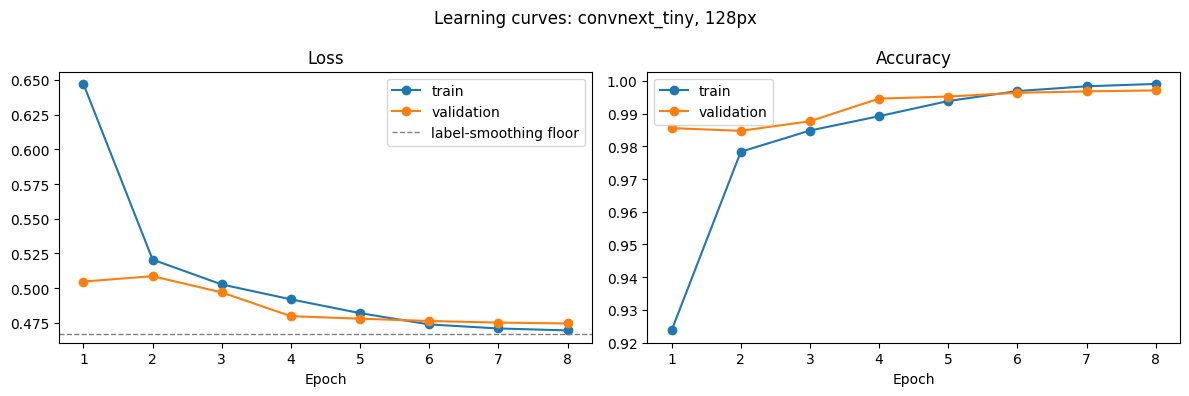

In [11]:
hist_df = pd.DataFrame(history)
hist_df.index = range(1, len(hist_df) + 1)
hist_df.index.name = "epoch"
print(hist_df.round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(hist_df.index, hist_df["train_loss"], "o-", label="train")
ax1.plot(hist_df.index, hist_df["val_loss"], "o-", label="validation")
ax1.axhline(0.467, color="grey", ls="--", lw=1, label="label-smoothing floor")
ax1.set_title("Loss"); ax1.set_xlabel("Epoch"); ax1.legend()

ax2.plot(hist_df.index, hist_df["train_acc"], "o-", label="train")
ax2.plot(hist_df.index, hist_df["val_acc"], "o-", label="validation")
ax2.set_title("Accuracy"); ax2.set_xlabel("Epoch"); ax2.legend()

plt.suptitle(f"Learning curves: {MODEL_NAME}, {CFG['img_size']}px")
plt.tight_layout(); plt.show()

hist_df.to_csv("/kaggle/working/history_baseline.csv")   # keep for the experiments table

val:   0%|          | 0/75 [00:00<?, ?it/s]

Best checkpoint -> val loss 0.4746 | val acc 0.9971

              precision    recall  f1-score   support

      CatEye     0.9995    0.9971    0.9983      2082
     CatFace     1.0000    1.0000    1.0000      1041
    CatMouth     0.9895    0.9990    0.9943      1041
     CatNose     0.9981    0.9846    0.9913      1041
      DogEye     0.9966    0.9994    0.9980      1736
     DogFace     0.9977    1.0000    0.9988       868
    DogMouth     0.9943    0.9988    0.9966       869
     DogNose     0.9988    0.9965    0.9977       869

    accuracy                         0.9971      9547
   macro avg     0.9968    0.9970    0.9969      9547
weighted avg     0.9971    0.9971    0.9971      9547



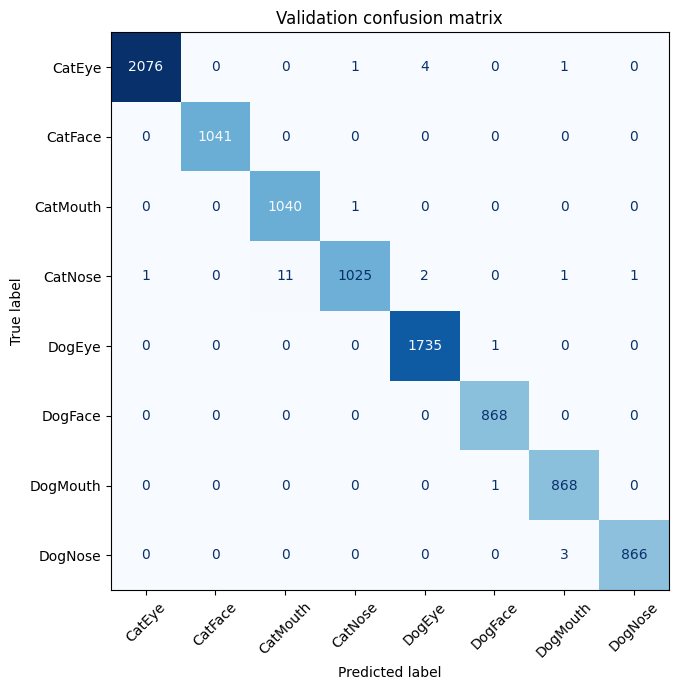

Misclassified: 28 of 9547


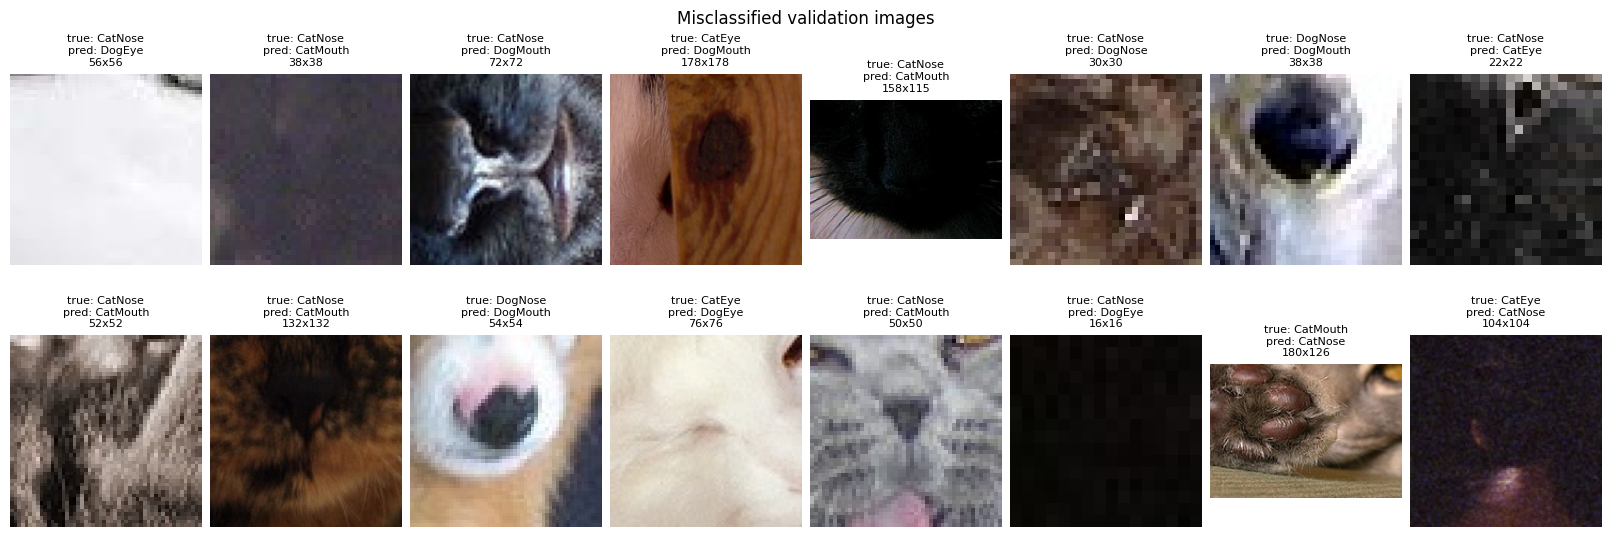

In [12]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Load the BEST checkpoint (not just the last epoch's weights)
model.load_state_dict(torch.load(CKPT_PATH, map_location=device))
va_loss, va_acc, val_preds, val_labels = evaluate(model, val_loader)
print(f"Best checkpoint -> val loss {va_loss:.4f} | val acc {va_acc:.4f}\n")

# Per-class precision, recall, F1
print(classification_report(val_labels, val_preds, target_names=CLASSES, digits=4))

# Confusion matrix
cm = confusion_matrix(val_labels, val_preds)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues",
                                                        xticks_rotation=45, colorbar=False)
ax.set_title("Validation confusion matrix")
plt.tight_layout(); plt.show()

# Show the misclassified images (original, un-augmented)
wrong = np.where(val_preds.numpy() != val_labels.numpy())[0]
print(f"Misclassified: {len(wrong)} of {len(val_df)}")
n_show = min(16, len(wrong))
fig, axes = plt.subplots(2, 8, figsize=(16, 5.5), constrained_layout=True)
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, wrong[:n_show]):
    img_id = int(val_df.iloc[i]["image_id"])
    img = Image.open(os.path.join(TRAIN_DIR, f"{img_id:05d}.jpg"))
    ax.imshow(img)
    ax.set_title(f"true: {CLASSES[val_labels[i]]}\npred: {CLASSES[val_preds[i]]}\n{img.size[0]}x{img.size[1]}",
                 fontsize=8)
fig.suptitle("Misclassified validation images")
plt.show()

In [13]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    all_preds, all_ids = [], []
    for x, img_ids in tqdm(loader, desc="test"):
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(x.to(device, non_blocking=True))
        all_preds.append(logits.argmax(1).cpu())
        all_ids.append(img_ids)
    return torch.cat(all_preds).numpy(), torch.cat(all_ids).numpy()

test_preds, test_ids = predict(model, test_loader)

# Build the submission in the exact sample_submission format
sub = pd.read_csv(os.path.join(BASE, "sample_submission.csv"))
assert (sub["image_id"].values == test_ids).all(), "ID order mismatch!"
sub["class"] = [idx_to_class[p] for p in test_preds]

# Safety checks before submitting
assert len(sub) == 29443
assert set(sub["class"]).issubset(set(CLASSES))
assert sub["image_id"].is_unique

SUB_PATH = "/kaggle/working/submission_baseline.csv"
sub.to_csv(SUB_PATH, index=False)
print(sub.head())
print("\nPredicted class distribution:\n", sub["class"].value_counts())
print(f"\nSaved {SUB_PATH}")

test:   0%|          | 0/231 [00:00<?, ?it/s]

   image_id     class
0         1    DogEye
1         2  DogMouth
2         3   DogNose
3         4   DogFace
4         5  CatMouth

Predicted class distribution:
 class
CatEye      6317
DogEye      5556
CatMouth    3272
CatFace     3126
CatNose     2883
DogFace     2808
DogMouth    2804
DogNose     2677
Name: count, dtype: int64

Saved /kaggle/working/submission_baseline.csv
